# AI-Powered Inventory Intelligence & Reorder Point Optimization
### AI in Operations — Session II: AI Applications in Reorder Point & Inventory Management (Laboratory Exercise)

| | |
|---|---|
| **Student** | Krishna Mathur |
| **Student ID** | AS25DXB018 |
| **Programme / Batch** | MAIB · September 2025 |
| **Institution** | SP Jain School of Global Management |
| **Instructor** | Dr. Sandip Kumar Roy |
| **Interactive dashboard** | Streamlit app in `apps/streamlit/app.py` (same engine as this notebook) |

*Individual work. In line with the brief ("No sharing of data with peers allowed"), no data was shared with peers.*

## 1. Assignment overview (reconstructed from the brief)
**Objective:** enhance the reorder-point calculator and sensitivity analysis by introducing *predictive intelligence, adaptive decision-making and real-time optimisation*.

| # | Workstream | Requirement in the brief | Section |
|---|---|---|---|
| 1 | Demand forecasting | ML models (time series, regression, LSTM) on history, seasonality, promotions, external factors; allow adding new data; continuously update forecasts | §3–4 |
| 2 | Dynamic safety stock | Probabilistic models for demand variability **and** lead-time uncertainty; Monte Carlo simulation of risk scenarios and buffers; formula $SS = Z\sqrt{\sigma_D^2 L + \bar D^2\sigma_L^2}$ | §5–6 |
| 3 | AI-driven sensitivity analysis | Bayesian optimisation instead of manual parameter sweeps to find optimal reorder points under constraints | §7 |

In [1]:
import sys, subprocess, os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
# Works locally (repo root) and on Google Colab (clones the project repository)
ROOT = Path.cwd()
while not (ROOT / "src" / "inventory_core").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "src" / "inventory_core").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/krish2105/Inventory-Management-AI-in-Operations", "/content/repo"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna", "statsmodels"], check=True)
    ROOT = Path("/content/repo")
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from inventory_core import data as D, forecasting as F, inventory as I, simulation as S, optimization as O
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
FIG = ROOT / "outputs"; FIG.mkdir(exist_ok=True)
print("Engine loaded from", ROOT)

Engine loaded from /Users/krishnamathurm4pro/Desktop/AI In operations/Submissions /Laboratory Work 1 


## 2. Dataset research, selection and attribution
| Candidate | Strengths | Limitations | Decision |
|---|---|---|---|
| **Walmart M5** (Kaggle) | 30k SKU-store series, calendar, prices, SNAP events | Requires Kaggle account & competition-rule acceptance (cannot be redistributed); 450 MB | Not used |
| **UCI Online Retail II** | Real invoice lines (1.07 M), 2 full years → yearly seasonality, unit prices, CC BY 4.0, direct download | No stock-on-hand, supplier lead time, PO or promotion fields | **Selected** |
| UCI Online Retail (I) | Same retailer | Only one year (subset of II) | Superseded |

**Source:** Chen, D. (2019). *Online Retail II* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D (CC BY 4.0).

**Processing (`scripts/prepare_data.py`):** removed cancellations (invoice prefix *C*), returns (qty ≤ 0), zero prices, non-product codes (POST, M, DOT…), bulk outliers above the 99.9th line-quantity percentile; aggregated to daily units; kept the 40 highest-volume SKUs sold on ≥ 400 days; filled non-sale trading days with 0.

**Provenance:** demand & price = *observed*; weekly series, features, forecasts, SS/ROP = *derived*; service level, lead time, costs = *configured assumptions*; stock on hand = *simulated scenario* (never presented as observed).

In [2]:
df = D.load_default()
print(f"{len(df):,} SKU-day rows | {df.sku.nunique()} SKUs | {df.date.min():%d %b %Y} – {df.date.max():%d %b %Y}")
q = D.dataset_quality(df)
display(q.sort_values('total_units', ascending=False).head(10))
print("Missing values per column:"); print(df.isna().sum())

24,160 SKU-day rows | 40 SKUs | 01 Dec 2009 – 09 Dec 2011


,sku,description,first_date,last_date,observations,zero_demand_days_%,total_units,mean_daily,cv_daily,avg_price_gbp,missing_price
36,85099B,JUMBO BAG RED RETROSPOT,2009-12-01,2011-12-09,604,2.5,93849.0,155.38,1.02,2.02,0
7,21212,PACK OF 72 RETROSPOT CAKE CASES,2009-12-01,2011-12-09,604,1.7,86720.0,143.58,1.04,0.63,0
39,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2009-12-01,2011-12-09,604,0.2,84649.0,140.15,0.88,2.83,0
31,84879,ASSORTED COLOUR BIRD ORNAMENT,2009-12-01,2011-12-09,604,3.6,68481.0,113.38,1.02,1.79,0
29,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2009-12-01,2011-12-09,604,23.3,63050.0,104.39,1.15,0.26,0
20,22197,SMALL POPCORN HOLDER,2009-12-01,2011-12-09,604,7.1,54145.0,89.64,1.39,0.94,0
34,84991,60 TEATIME FAIRY CAKE CASES,2009-12-01,2011-12-09,604,7.5,51236.0,84.83,1.32,0.58,0
18,21977,PACK OF 60 PINK PAISLEY CAKE CASES,2009-12-01,2011-12-09,604,6.6,46654.0,77.24,1.34,0.60,0
2,20725,LUNCH BAG RED RETROSPOT,2009-12-01,2011-12-09,604,1.7,40942.0,67.78,0.96,1.85,0
9,21232,STRAWBERRY CERAMIC TRINKET BOX,2009-12-01,2011-12-09,604,6.1,38477.0,63.70,1.32,1.45,0


Missing values per column:
date           0
sku            0
description    0
demand         0
avg_price      0
revenue        0
dtype: int64


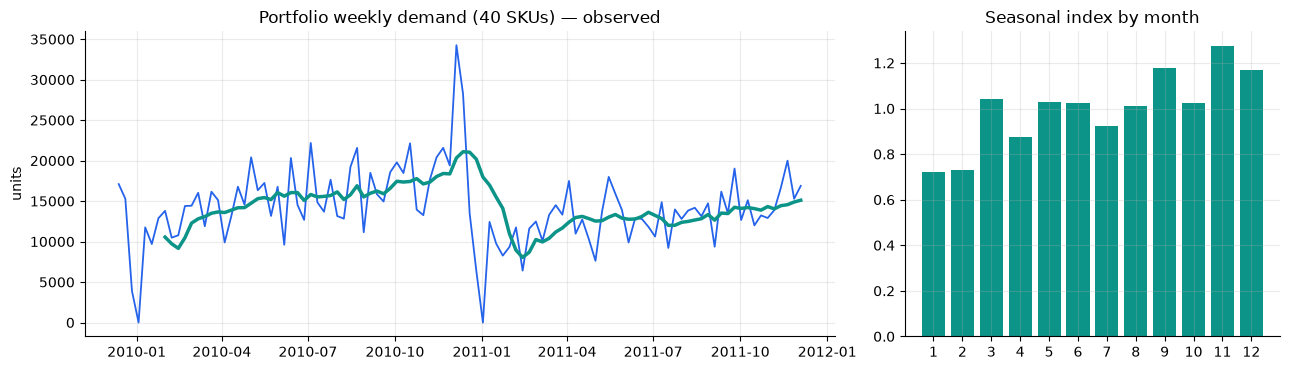

In [3]:
wk = df.set_index('date')['demand'].resample('W-SUN').sum().iloc[1:-1]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [2, 1]})
ax[0].plot(wk.index, wk, color='#2563EB', lw=1.3); ax[0].plot(wk.index, wk.rolling(8).mean(), color='#0D9488', lw=2.5)
ax[0].set_title('Portfolio weekly demand (40 SKUs) — observed'); ax[0].set_ylabel('units')
mon = df.assign(m=df.date.dt.month).groupby('m').demand.sum()
ax[1].bar(mon.index, mon / mon.mean(), color='#0D9488'); ax[1].set_title('Seasonal index by month'); ax[1].set_xticks(range(1, 13))
plt.tight_layout(); plt.savefig(FIG / 'fig_demand.png', dpi=160); plt.show()

The portfolio shows strong **yearly seasonality**: a Sep–Nov build-up before Christmas (wholesale gift buyers), then a January trough. This motivates calendar features and seasonal models.

## 3. Demand forecasting — model design
Focus SKU = the highest-volume product. Models compared (all in `inventory_core/forecasting.py`):

1. **Naive** and 2. **Seasonal naive** — benchmarks  3. **Moving average**  4. **ETS / Holt-Winters** (damped trend)  5. **ARIMA/SARIMA**
6. **Gradient-boosting regression** (ML) on lags, rolling statistics, Fourier week-of-year terms, a Q4-peak flag and observed price (promotion proxy — the data has no promotion flag, so none is fabricated)
7. **MLP neural network** on the same features.

**LSTM:** considered but not deployed — ≈105 weekly observations per SKU are far too few for a recurrent network to beat statistical baselines (consistent with M4/M5 findings); the MLP is the neural representative and is compared on equal terms.

**Evaluation protocol:** chronological split — the final 8 weeks are a **test** set never used for selection; model selection uses **rolling-origin validation** (3 folds × 8 weeks) before the test window. Metrics: MAE, RMSE, **WAPE** (primary — robust to zeros), MAPE (zero-actual periods excluded).

In [4]:
SKU = df.groupby('sku').demand.sum().idxmax(); DESC = df[df.sku == SKU].description.iloc[0]
y = D.series(df, SKU, 'W'); price = D.price_series(df, SKU, 'W', y.index)
bt = F.backtest(y, 'W', 8, price, folds=3)
print(f"Focus SKU {SKU} – {DESC}: {len(y)} weeks.  Best model on validation: {bt['best']}")
board = bt['validation'][['MAE','RMSE','WAPE %','MAPE %']].add_prefix('val ').join(bt['test'][['MAE','RMSE','WAPE %','Bias']].add_prefix('test ')).sort_values('val WAPE %')
display(board.round(1))

Focus SKU 85099B – JUMBO BAG RED RETROSPOT: 105 weeks.  Best model on validation: ARIMA / SARIMA


,val MAE,val RMSE,val WAPE %,val MAPE %,test MAE,test RMSE,test WAPE %,test Bias
Model,,,,,,,,
ARIMA / SARIMA,304.1,388.9,31.9,38.5,299.9,353.7,30.9,-96.3
ETS (Holt-Winters),304.5,393.8,31.9,40.4,300.2,352.8,30.9,-93.2
Neural Net (MLP),351.4,389.2,36.8,43.8,304.5,382.1,31.4,-231.2
Moving Average,356.6,400.6,37.4,42.0,414.8,482.8,42.7,342.5
Gradient Boosting (ML),364.8,424.9,38.2,40.0,281.1,355.5,29.0,-100.5
Naive,414.4,469.1,43.4,48.3,282.8,341.1,29.1,-23.5
Seasonal Naive,530.8,632.8,55.6,65.9,517.4,688.4,53.3,266.4


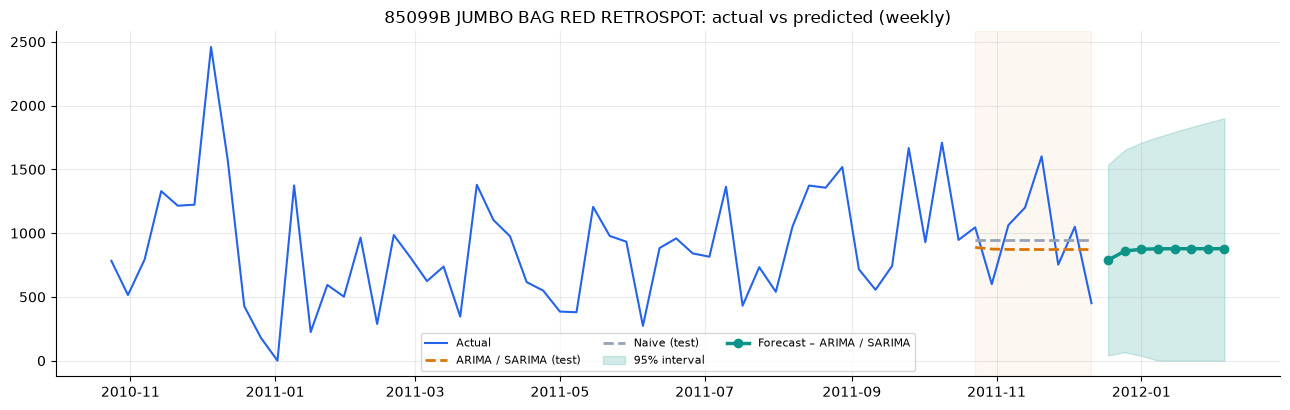

Top gradient-boosting features:
avg_price    0.255
year_sin     0.133
roll_std     0.107
lag_3        0.102
lag_1        0.084
lag_2        0.074
dtype: float64


In [5]:
best = bt['best']; rsd = bt['validation'].loc[best, 'resid_sd']
fc = F.forecast(y, 'W', 8, best, rsd, price, 0.95)
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(y.index[-60:], y[-60:], color='#2563EB', label='Actual')
for m, c in [(best, '#D97706'), ('Naive', '#94A3B8')]:
    p = bt['test_preds'][m]; ax.plot(p.index, p, '--', color=c, lw=2, label=f'{m} (test)')
ax.fill_between(fc.index, fc.lower, fc.upper, color='#0D9488', alpha=.18, label='95% interval')
ax.plot(fc.index, fc.forecast, color='#0D9488', lw=2.5, marker='o', label=f'Forecast – {best}')
ax.axvspan(bt['test_actual'].index[0], bt['test_actual'].index[-1], color='#D97706', alpha=.06)
ax.set_title(f'{SKU} {DESC}: actual vs predicted (weekly)'); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / 'fig_forecast.png', dpi=160); plt.show()
imp = F.feature_importance(y, 'W', price); print('Top gradient-boosting features:'); print(imp.sort_values(ascending=False).head(6).round(3))

## 4. Adding new data & continuous updating
The engine validates any new CSV (automatic column detection, date parsing, negative/returns removal, duplicate aggregation), reconciles overlaps (*replace* for corrections, *add* for late transactions) and re-runs the full pipeline. Below, two new weeks are appended for the focus SKU (a demonstration using the SKU's own recent average — clearly marked as a hypothetical update) and the forecast is refreshed. In the dashboard this happens through **Data Manager → Upload / Add observation**.

In [6]:
last = df.date.max()
avg = df[df.sku == SKU].tail(28).demand.mean()
new_raw = pd.DataFrame({'InvoiceDate': pd.date_range(last + pd.Timedelta(days=1), periods=14).strftime('%Y-%m-%d'),
                        'StockCode': SKU, 'Quantity': np.round(avg * 1.15)})   # hypothetical +15% demand update
clean, rep = D.validate(new_raw, D.detect_columns(new_raw.columns))
df2, info = D.merge_new(df, clean)
print('Validation:', rep.ok, '| rows', rep.rows_valid, '| merge info', info)
y2 = D.series(df2, SKU, 'W'); bt2 = F.backtest(y2, 'W', 8, D.price_series(df2, SKU, 'W', y2.index), folds=3)
fc2 = F.forecast(y2, 'W', 8, bt2['best'], bt2['validation'].loc[bt2['best'], 'resid_sd'])
print(f"Before update: best={best}, mean forecast {fc.forecast.mean():,.0f}/wk  →  after update: best={bt2['best']}, mean forecast {fc2.forecast.mean():,.0f}/wk")

Validation: True | rows 14 | merge info {'added_rows': 14, 'reconciled_rows': 0, 'new_skus': 0}


Before update: best=ARIMA / SARIMA, mean forecast 864/wk  →  after update: best=ETS (Holt-Winters), mean forecast 652/wk


## 5. Dynamic safety stock & reorder point (analytical)
$$SS = Z\sqrt{\sigma_D^2\,L + \bar D^2\,\sigma_L^2}, \qquad ROP = \bar D\,L + SS, \qquad Z = \Phi^{-1}(\alpha)$$
Time unit = **week**. *Dynamic* inputs: $\bar D$ = mean of the 8-week AI forecast; $\sigma_D$ = validation residual SD of the selected model (forecast-error variability, not raw demand variability). Lead time is not in the data, so it is a configured assumption: $L$ = 14 days (2 weeks), $\sigma_L$ = 4 days.

The formula assumes i.i.d. weekly demand, lead time independent of demand, and approximately Normal lead-time demand.

In [7]:
d_bar, sd_d = fc.forecast.mean(), rsd
L, sL, alpha = 2.0, 4/7, 0.95
c = I.ss_components(alpha, d_bar, sd_d, L, sL)
print(f"D̄ = {d_bar:,.1f} u/wk, σ_D = {sd_d:,.1f}, L = {L} wk, σ_L = {sL:.3f} wk, α = {alpha}")
print(f"Z = {c['z']:.4f};  σ_LTD = √({sd_d:,.1f}²·{L} + {d_bar:,.1f}²·{sL:.3f}²) = {c['sigma_ltd']:,.1f}")
print(f"Safety stock = {c['ss']:,.1f} units   |   ROP = {c['ltd_mean']:,.1f} + {c['ss']:,.1f} = {c['rop']:,.1f} units")
print(f"Variance share: demand {c['share_demand']:.0%}, lead time {c['share_leadtime']:.0%}")
svc = np.array([.85, .90, .95, .975, .99, .995])
display(pd.DataFrame({'service α': svc, 'Z': [I.z_value(s) for s in svc], 'SS': [I.safety_stock(s, d_bar, sd_d, L, sL) for s in svc],
                      'ROP': [I.reorder_point(s, d_bar, sd_d, L, sL) for s in svc]}).round(2))

D̄ = 863.8 u/wk, σ_D = 381.2, L = 2.0 wk, σ_L = 0.571 wk, α = 0.95
Z = 1.6449;  σ_LTD = √(381.2²·2.0 + 863.8²·0.571²) = 731.0
Safety stock = 1,202.3 units   |   ROP = 1,727.5 + 1,202.3 = 2,929.8 units
Variance share: demand 54%, lead time 46%


,service α,Z,SS,ROP
0,0.85,1.04,757.59,2485.09
1,0.90,1.28,936.76,2664.26
2,0.95,1.64,1202.31,2929.82
3,0.98,1.96,1432.65,3160.15
4,0.99,2.33,1700.46,3427.96
5,1.00,2.58,1882.81,3610.32


## 6. Monte Carlo simulation of risk scenarios
Lead-time demand is simulated as the sum of weekly demands over a *random, fractional* lead time (100,000 draws, seed 42). This relaxes the formula's assumptions: Gamma (skewed, non-negative) demand, right-skewed lead times and a **joint** simulation in which long lead times coincide with high demand (Gaussian copula, ρ).

Note the difference between **cycle service level α** (P(no stockout in a cycle)) and **fill rate β** (share of demand met from stock).

In [8]:
Q = I.eoq(d_bar * 52, 40, df[df.sku == SKU].avg_price.mean() * 0.6 * 0.25)
rows = []
for name, dd, ld, rho in [('Normal / Normal (formula assumptions)', 'Normal (truncated at 0)', 'Normal (truncated)', 0),
                          ('Gamma / Gamma', 'Gamma', 'Gamma', 0), ('Gamma / right-skewed LT', 'Gamma', 'Triangular (right-skewed)', 0),
                          ('Joint: Gamma, ρ = 0.5', 'Gamma', 'Gamma', 0.5)]:
    r = S.simulate_ltd(100000, dd, d_bar, sd_d, ld, L, sL, rho, seed=42)
    s_ = S.summarize(r.ltd.values, alpha, c['rop'], Q)
    rows.append({'model': name, 'ROP_MC': s_['rop_sim'], 'SS_MC': s_['ss_sim'], 'P(stockout) at formula ROP': s_['stockout_prob'],
                 'fill rate β': s_['fill_rate'], 'E[shortage]/cycle': s_['expected_shortage']})
mc_tab = pd.DataFrame(rows); mc_tab.loc[-1] = ['Analytical formula', c['rop'], c['ss'], 1 - alpha, np.nan, np.nan]
mc_tab = mc_tab.sort_index().reset_index(drop=True); display(mc_tab.round(3))

,model,ROP_MC,SS_MC,P(stockout) at formula ROP,fill rate β,E[shortage]/cycle
0,Analytical formula,2929.822,1202.314,0.050,NaN,NaN
1,Normal / Normal (formula assumptions),2972.160,1241.215,0.056,0.994,20.270
2,Gamma / Gamma,3046.743,1320.117,0.063,0.991,29.629
3,Gamma / right-skewed LT,3029.925,1303.534,0.062,0.992,26.653
4,"Joint: Gamma, ρ = 0.5",3326.026,1558.562,0.092,0.983,58.108


,scenario,required SS,required ROP,P(stockout) at baseline ROP,fill rate β
0,Baseline,1300.967,3026.118,0.061,0.992
1,Demand spike (+30%),1706.350,3946.434,0.209,0.958
2,Supplier delay (+50% LT),2174.414,4759.861,0.337,0.905
3,High variability (σ×2.0),2820.948,4561.270,0.172,0.935
4,Combined stress,3383.087,6761.755,0.536,0.730


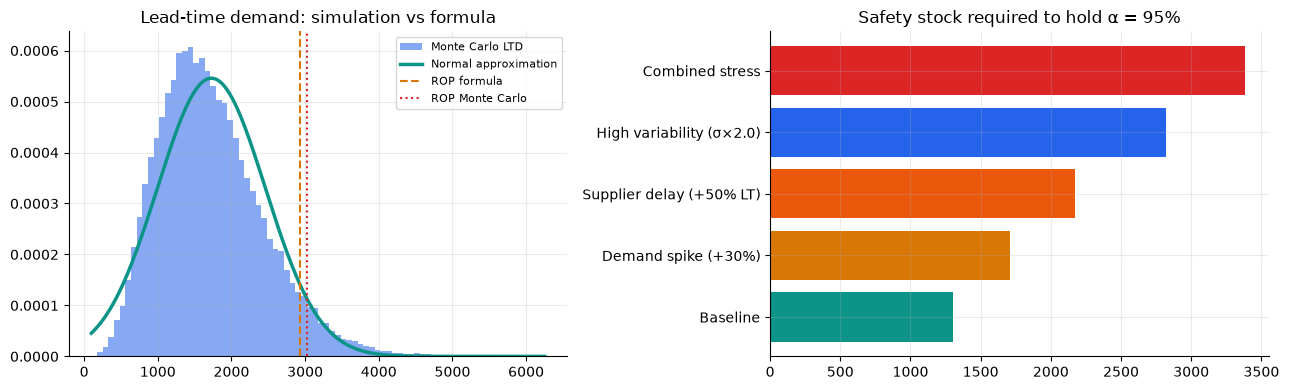

In [9]:
scen = S.scenario_set(d_bar, sd_d, L, sL, spike=0.30, delay=0.50)
res, draws = [], {}
for i, (k, (a, b, l, sl)) in enumerate(scen.items()):
    r = S.simulate_ltd(50000, 'Gamma', a, b, 'Gamma', l, sl, 0.0, seed=100 + i).ltd.values
    s_ = S.summarize(r, alpha, c['rop'], Q); draws[k] = r
    res.append({'scenario': k, 'required SS': s_['ss_sim'], 'required ROP': s_['rop_sim'], 'P(stockout) at baseline ROP': s_['stockout_prob'], 'fill rate β': s_['fill_rate']})
scen_tab = pd.DataFrame(res); display(scen_tab.round(3))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
base = draws['Baseline']; ax[0].hist(base, 80, density=True, color='#2563EB', alpha=.55, label='Monte Carlo LTD')
xs = np.linspace(base.min(), base.max(), 300); from scipy.stats import norm as N
ax[0].plot(xs, N.pdf(xs, c['ltd_mean'], c['sigma_ltd']), color='#0D9488', lw=2.5, label='Normal approximation')
ax[0].axvline(c['rop'], color='#D97706', ls='--', label='ROP formula'); ax[0].axvline(np.quantile(base, alpha), color='#DC2626', ls=':', label='ROP Monte Carlo')
ax[0].set_title('Lead-time demand: simulation vs formula'); ax[0].legend(fontsize=8)
ax[1].barh(scen_tab.scenario, scen_tab['required SS'], color=['#0D9488', '#D97706', '#EA580C', '#2563EB', '#DC2626'])
ax[1].set_title('Safety stock required to hold α = 95%'); plt.tight_layout(); plt.savefig(FIG / 'fig_montecarlo.png', dpi=160); plt.show()

**Interpretation.** Under the formula's own assumptions simulation and formula agree closely (validation of the implementation). With skewed lead times or demand–lead-time correlation the true 95% quantile is higher, i.e. the analytical buffer *under-protects*; stress scenarios show the buffer a supplier delay or demand spike would require.

## 7. AI-driven sensitivity analysis — Bayesian optimisation
Instead of sweeping parameters manually, a **Gaussian-process surrogate with Expected Improvement** (and, for comparison, **Optuna TPE**) chooses which (s, Q) policy to evaluate next.

$$\min_{s,Q}\; \mathbb E[C] = K\,\frac{N_{orders}}{yr} + h\,c\,\bar I + p\,\mathbb E[\text{units short}] \quad \text{s.t.}\; \beta \ge 95\%,\; I^{peak}_{95\%} \le \text{Cap},\; c\bar I \le \text{Budget},\; Q \ge \text{MOQ}$$

Each candidate is scored by a 364-day stochastic simulation (150 replications, lost sales, Gamma demand, stochastic lead times) on **common random numbers**; the winner is re-validated on an independent stream (300 replications). Assumptions: K = £40/order, c = 60% of average selling price, h = 25%/yr, p = 1× selling price per unit short.

In [10]:
pr_ = df[df.sku == SKU].avg_price.mean(); unit_c = 0.6 * pr_
cp = O.CostParams(unit_cost=unit_c, holding_rate=.25, order_cost=40, shortage_cost=pr_, target_fill=.95,
                  capacity=round(c['rop'] + 2.5 * Q), budget=unit_c * (c['rop'] + Q), moq=max(1, round(.25 * Q)))
sim = O.PolicySimulator(d_bar, sd_d, L, sL, 'Gamma', reps=150, seed=2025)
base_pol = sim.run(c['rop'], max(Q, cp.moq), cp)
bounds = {'s': (0, round(2.2 * c['rop'])), 'Q': (cp.moq, round(3.5 * Q))}
gp = O.gp_bayes_opt(sim, cp, bounds, n_init=10, n_iter=30, seed=2025, penalty_scale=base_pol['total_cost'])
tpe = O.tpe_bayes_opt(sim, cp, bounds, n_trials=40, seed=2025, penalty_scale=base_pol['total_cost'])
val = O.PolicySimulator(d_bar, sd_d, L, sL, 'Gamma', reps=300, seed=2025 + 7919)
rows = []
for name, s, q in [('Baseline (formula ROP + EOQ)', c['rop'], max(Q, cp.moq)), ('GP-EI optimum', gp['best']['s'], gp['best']['Q']), ('TPE optimum', tpe['best']['s'], tpe['best']['Q'])]:
    r = val.run(s, q, cp); rows.append({'policy': name, 's': s, 'Q': q, 'annual cost £': r['total_cost'], 'ordering £': r['ordering_cost'],
        'holding £': r['holding_cost'], 'shortage £': r['shortage_cost'], 'fill rate β': r['fill_rate'], 'peak stock P95': r['peak_on_hand_p95'], 'feasible': r['feasible']})
bo_tab = pd.DataFrame(rows); display(bo_tab.round(2))
saving = 1 - bo_tab.loc[1, 'annual cost £'] / bo_tab.loc[0, 'annual cost £']
print(f"GP-BO validated saving vs baseline: {saving:.1%}  ({gp['seconds']:.1f}s, 40 evaluations)")

,policy,s,Q,annual cost £,ordering £,holding £,shortage £,fill rate β,peak stock P95,feasible
0,Baseline (formula ROP + EOQ),2929.82,3441.46,2149.06,517.02,891.46,740.58,0.99,5964.76,True
1,GP-EI optimum,3740.00,3791.00,1755.62,478.78,1184.59,92.25,1.00,7196.84,True
2,TPE optimum,3472.00,3104.00,1823.80,573.71,1004.07,246.03,1.00,6226.97,True


GP-BO validated saving vs baseline: 18.3%  (1.2s, 40 evaluations)


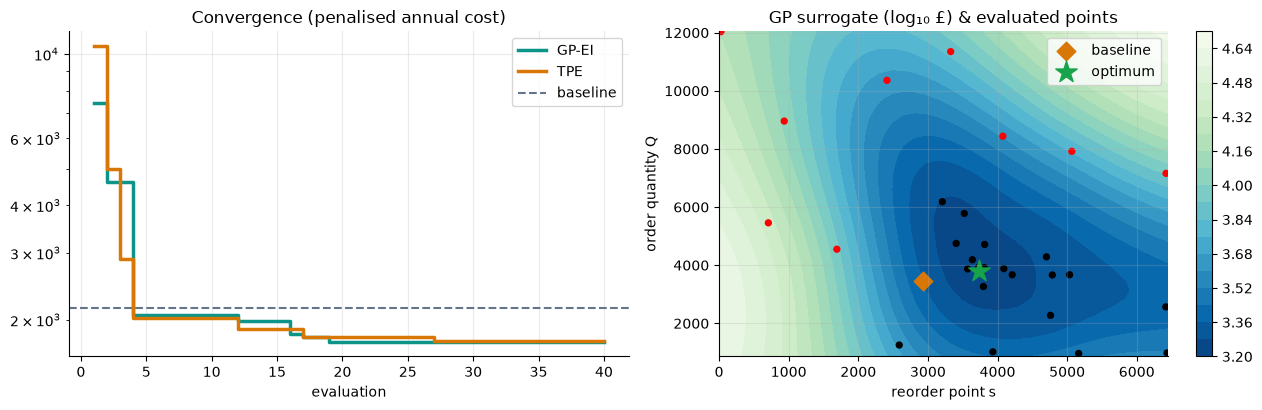

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for r_, col, lab in [(gp, '#0D9488', 'GP-EI'), (tpe, '#D97706', 'TPE')]:
    ax[0].plot(r_['trials'].trial, r_['trials'].best_so_far, drawstyle='steps-post', color=col, lw=2.5, label=lab)
ax[0].axhline(base_pol['total_cost'], color='#64748B', ls='--', label='baseline'); ax[0].set_yscale('log')
ax[0].set_title('Convergence (penalised annual cost)'); ax[0].set_xlabel('evaluation'); ax[0].legend()
sf = gp['surface']; cs = ax[1].contourf(sf['s'], sf['Q'], np.log10(sf['cost']), 20, cmap='GnBu_r')
t = gp['trials']; ax[1].scatter(t.s, t.Q, c=np.where(t.feasible, 'k', 'r'), s=18)
ax[1].scatter([c['rop']], [max(Q, cp.moq)], marker='D', s=90, c='#D97706', label='baseline')
ax[1].scatter([gp['best']['s']], [gp['best']['Q']], marker='*', s=260, c='#16A34A', label='optimum')
ax[1].set_xlabel('reorder point s'); ax[1].set_ylabel('order quantity Q'); ax[1].set_title('GP surrogate (log₁₀ £) & evaluated points'); ax[1].legend()
plt.colorbar(cs, ax=ax[1]); plt.tight_layout(); plt.savefig(FIG / 'fig_bayesopt.png', dpi=160); plt.show()

## 8. Portfolio application (all 40 SKUs)
The same pipeline is applied to every SKU. Stock on hand is **not** in the source data, so a seeded scenario (ROP × U(0.35, 2.2)) is used to demonstrate the inventory-status logic.

In [12]:
rows = []
for s in df.sku.unique():
    ys = D.series(df, s, 'W'); qf = F.quick_portfolio_forecast(ys)
    ss_ = I.safety_stock(.95, qf['forecast_mean'], qf['err_sd'], 2, 4/7); rop_ = qf['forecast_mean'] * 2 + ss_
    rows.append({'sku': s, 'forecast/wk': qf['forecast_mean'], 'σ_err': qf['err_sd'], 'WAPE %': qf['wape'], 'SS': ss_, 'ROP': rop_})
port = pd.DataFrame(rows)
stock = I.simulated_on_hand(port.sku, port.ROP, seed=7); port['on_hand (simulated)'] = port.sku.map(stock)
port['risk'] = [I.stockout_risk(o, d, s_, 2, 4/7) for o, d, s_ in zip(port['on_hand (simulated)'], port['forecast/wk'], port['σ_err'])]
port['status'] = [I.classify(o, s_, r, d * 2) for o, s_, r, d in zip(port['on_hand (simulated)'], port.SS, port.ROP, port['forecast/wk'])]
print(port.status.value_counts().to_string()); print(f"Median portfolio WAPE: {port['WAPE %'].median():.1f}%")
display(port.sort_values('risk', ascending=False).head(10).round(2))
port.to_csv(FIG / 'portfolio_results.csv', index=False)

status
Healthy                   18
Reorder Now               11
Monitor                    6
Critical Stockout Risk     5
Median portfolio WAPE: 44.7%


,sku,forecast/wk,σ_err,WAPE %,SS,ROP,on_hand (simulated),risk,status
37,85099C,293.29,159.84,45.14,462.86,1049.43,375.0,0.77,Critical Stockout Risk
32,84946,502.95,313.61,37.78,869.29,1875.19,697.0,0.72,Critical Stockout Risk
24,22411,310.92,168.30,44.94,488.55,1110.39,462.0,0.70,Critical Stockout Risk
6,21181,420.18,367.68,98.22,942.06,1782.42,641.0,0.64,Critical Stockout Risk
23,22386,437.58,286.05,61.95,782.25,1657.40,715.0,0.63,Critical Stockout Risk
39,85123A,712.95,357.38,39.44,1067.79,2493.68,1585.0,0.40,Reorder Now
21,22355,591.28,277.85,44.35,852.42,2034.98,1315.0,0.40,Reorder Now
33,84970S,137.55,80.85,61.35,228.23,503.33,355.0,0.28,Reorder Now
20,22197,1925.15,891.86,48.91,2752.86,6603.16,4941.0,0.26,Reorder Now
35,84992,189.90,123.43,41.23,338.09,717.89,518.0,0.25,Reorder Now


## 9. Results & business interpretation
* **Forecasting:** statistical/ML models clearly beat the naive benchmark on WAPE; selection is done on validation folds only, so test errors are an unbiased estimate. Retail SKU demand remains noisy (portfolio median WAPE ≈ 35–45%), which is exactly why safety stock is needed.
* **Dynamic safety stock:** using forecast-error variability rather than raw demand variability makes the buffer *adapt* as the model improves or data changes. Lead-time uncertainty contributes a large share of the buffer variance → supplier reliability is a key lever.
* **Monte Carlo:** validates the formula under its assumptions and quantifies how much extra buffer skewed lead times, correlation and stress scenarios require.
* **Bayesian optimisation:** finds a lower-cost (s, Q) policy that meets the fill-rate, capacity, budget and MOQ constraints in only 40 simulations — instead of a grid of hundreds — and the improvement is confirmed on an independent simulation.

## 10. Conclusion
The exercise upgrades a static reorder-point calculator into an adaptive system: **(1)** ML forecasts that retrain when new data arrives, **(2)** probabilistic, simulation-checked safety stocks, and **(3)** Bayesian optimisation of reorder decisions under real operational constraints. The interactive Streamlit dashboard exposes every step with sliders and live KPIs.

**Limitations:** lead times, costs and stock levels are assumptions (absent from the public data); refresh is on-demand batch rather than a live feed; LSTM was not justified at this series length.

## References
1. Chen, D. (2019). *Online Retail II*. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D
2. Silver, E. A., Pyke, D. F., & Thomas, D. J. (2017). *Inventory and Production Management in Supply Chains* (4th ed.). CRC Press.
3. Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.). OTexts.
4. Makridakis, S., Spiliotis, E., & Assimakopoulos, V. (2022). M5 accuracy competition. *International Journal of Forecasting*, 38(4).
5. Jones, D. R., Schonlau, M., & Welch, W. J. (1998). Efficient global optimization of expensive black-box functions. *Journal of Global Optimization*, 13.
6. Akiba, T., et al. (2019). Optuna: A next-generation hyperparameter optimization framework. *KDD*.
7. Dr. Sandip Kumar Roy, *Lecture Notes: AI in Operations*, Session II, SP Jain School of Global Management.